# 1. Libraries and Data Loading

In [1]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics import precision_score, recall_score

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

data = pd.read_csv(r'credit_score.csv')
data.head()

,ID,CustomerID,Month,Name,Age,SSN,Occupation,AnnualIncome,MonthlyInhandSalary,NumBankAccounts,...,ChangedCreditLimit,NumCreditInquiries,OutstandingDebt,CreditUtilizationRatio,PaymentofMinAmount,TotalEMIpermonth,Amountinvestedmonthly,PaymentBehaviour,MonthlyBalance,CreditScore
0,0x1602,CUS0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,11.27,4.0,809.98,26.822620,No,49.574949,80.415295,HighspentSmallvaluepayments,312.494089,Good
1,0x1603,CUS0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,11.27,4.0,809.98,31.944960,No,49.574949,118.280222,LowspentLargevaluepayments,284.629163,Good
2,0x1604,CUS0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,...,NaN,4.0,809.98,28.609352,No,49.574949,81.699521,LowspentMediumvaluepayments,331.209863,Good
3,0x1605,CUS0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,6.27,4.0,809.98,31.377862,No,49.574949,199.458074,LowspentSmallvaluepayments,223.451310,Good
4,0x1606,CUS0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,11.27,4.0,809.98,24.797347,No,49.574949,41.420153,HighspentMediumvaluepayments,341.489231,Good


# 2. Descriptive Statistics

In [2]:
pd.set_option('display.max_columns', None)

data.describe(include='all')

,ID,CustomerID,Month,Name,Age,SSN,Occupation,AnnualIncome,MonthlyInhandSalary,NumBankAccounts,NumCreditCard,InterestRate,NumofLoan,TypeofLoan,Delayfromduedate,NumofDelayedPayment,ChangedCreditLimit,NumCreditInquiries,OutstandingDebt,CreditUtilizationRatio,PaymentofMinAmount,TotalEMIpermonth,Amountinvestedmonthly,PaymentBehaviour,MonthlyBalance,CreditScore
count,87495,87495,87495,78779,87495.000000,87495,81317,8.749500e+04,74319.000000,87495.000000,87495.000000,87495.000000,87495.000000,77583,87495.000000,81400.000000,85654.000000,85789.000000,87495.000000,87495.000000,87495,87495.000000,79786.000000,87495,86437.000000,87495
unique,87495,12500,8,10139,NaN,12501,15,NaN,NaN,NaN,NaN,NaN,NaN,6260,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,NaN,7,NaN,3
top,0x25fec,CUS0x132f,January,Langep,NaN,#F%$D@*&8,Lawyer,NaN,NaN,NaN,NaN,NaN,NaN,Not Specified,NaN,NaN,NaN,NaN,NaN,NaN,Yes,NaN,NaN,LowspentSmallvaluepayments,NaN,Standard
freq,1,8,10970,41,NaN,4857,5762,NaN,NaN,NaN,NaN,NaN,NaN,1208,NaN,NaN,NaN,NaN,NaN,NaN,45810,NaN,NaN,22237,NaN,46651
mean,NaN,NaN,NaN,NaN,110.467364,NaN,NaN,1.802404e+05,4193.181285,17.112646,22.664792,73.050871,7.019841,NaN,21.060403,30.904324,10.385851,27.734302,1426.716635,32.290526,NaN,1388.517947,195.482486,NaN,402.281023,NaN
std,NaN,NaN,NaN,NaN,686.549658,NaN,NaN,1.455212e+06,3179.195651,117.428586,129.806747,467.727237,60.352339,NaN,14.864558,225.495250,6.776714,193.011903,1155.824064,5.112418,NaN,8248.832131,199.357752,NaN,213.309331,NaN
min,NaN,NaN,NaN,NaN,-500.000000,NaN,NaN,7.005930e+03,303.645417,-1.000000,0.000000,1.000000,0.000000,NaN,-5.000000,-3.000000,-6.490000,0.000000,0.230000,20.000000,NaN,0.000000,0.000000,NaN,0.007760,NaN
25%,NaN,NaN,NaN,NaN,24.000000,NaN,NaN,1.943348e+04,1626.677917,3.000000,4.000000,8.000000,1.000000,NaN,10.000000,9.000000,5.340000,3.000000,566.400000,28.059063,NaN,30.453014,72.220853,NaN,270.107156,NaN
50%,NaN,NaN,NaN,NaN,33.000000,NaN,NaN,3.757975e+04,3095.905000,6.000000,5.000000,13.000000,3.000000,NaN,18.000000,14.000000,9.410000,6.000000,1166.230000,32.322206,NaN,69.285581,128.921405,NaN,336.698600,NaN
75%,NaN,NaN,NaN,NaN,42.000000,NaN,NaN,7.288608e+04,5967.930000,7.000000,7.000000,20.000000,5.000000,NaN,28.000000,18.000000,14.840000,9.000000,1948.980000,36.495606,NaN,161.405543,236.802042,NaN,470.180816,NaN


# 3. Data Types

In [3]:
data.dtypes

ID                         object
CustomerID                 object
Month                      object
Name                       object
Age                         int64
SSN                        object
Occupation                 object
AnnualIncome              float64
MonthlyInhandSalary       float64
NumBankAccounts             int64
NumCreditCard               int64
InterestRate                int64
NumofLoan                   int64
TypeofLoan                 object
Delayfromduedate            int64
NumofDelayedPayment       float64
ChangedCreditLimit        float64
NumCreditInquiries        float64
OutstandingDebt           float64
CreditUtilizationRatio    float64
PaymentofMinAmount         object
TotalEMIpermonth          float64
Amountinvestedmonthly     float64
PaymentBehaviour           object
MonthlyBalance            float64
CreditScore                object
dtype: object

# 4. Target Definition (Poor = 1)

In [4]:
data['score'] = np.where(data['CreditScore'] != 'Poor', 0, 1)
data.score.value_counts()

score
0    62145
1    25350
Name: count, dtype: int64

# 5. Removal of Non-Informative Columns

In [5]:
data.drop(['ID', 'CustomerID', 'Name', 'TypeofLoan', 'SSN', 'CreditScore'], axis=1, inplace=True)

# 6. Missing Value Analysis

In [6]:
data.isnull().sum()

Month                         0
Age                           0
Occupation                 6178
AnnualIncome                  0
MonthlyInhandSalary       13176
NumBankAccounts               0
NumCreditCard                 0
InterestRate                  0
NumofLoan                     0
Delayfromduedate              0
NumofDelayedPayment        6095
ChangedCreditLimit         1841
NumCreditInquiries         1706
OutstandingDebt               0
CreditUtilizationRatio        0
PaymentofMinAmount            0
TotalEMIpermonth              0
Amountinvestedmonthly      7709
PaymentBehaviour              0
MonthlyBalance             1058
score                         0
dtype: int64

# 7. Missing Value Imputation

In [7]:
for i in data.columns:
    if data[i].dtype == 'object':
        data[i] = data[i].fillna(data[i].mode()[0])
    else:
        data[i] = data[i].fillna(data[i].mean())

data.isnull().sum()

Month                     0
Age                       0
Occupation                0
AnnualIncome              0
MonthlyInhandSalary       0
NumBankAccounts           0
NumCreditCard             0
InterestRate              0
NumofLoan                 0
Delayfromduedate          0
NumofDelayedPayment       0
ChangedCreditLimit        0
NumCreditInquiries        0
OutstandingDebt           0
CreditUtilizationRatio    0
PaymentofMinAmount        0
TotalEMIpermonth          0
Amountinvestedmonthly     0
PaymentBehaviour          0
MonthlyBalance            0
score                     0
dtype: int64

# 8. Numeric and Categoric Variables

In [8]:
for i in data.columns:
    if data[i].dtypes != object:
        print(i)

Age
AnnualIncome
MonthlyInhandSalary
NumBankAccounts
NumCreditCard
InterestRate
NumofLoan
Delayfromduedate
NumofDelayedPayment
ChangedCreditLimit
NumCreditInquiries
OutstandingDebt
CreditUtilizationRatio
TotalEMIpermonth
Amountinvestedmonthly
MonthlyBalance
score


In [9]:
for i in data.columns:
    if data[i].dtypes == object:
        print(i)

Month
Occupation
PaymentofMinAmount
PaymentBehaviour


# 9. Weight of Evidence (WoE) Transformation

In [10]:
for var in data.columns:
    if var == 'score':
        continue

    if data[var].dtypes != object:
        q1 = data[var].quantile(0.25)
        q2 = data[var].quantile(0.5)
        q3 = data[var].quantile(0.75)

        ranges = [-np.inf, q1, q2, q3, np.inf]
        data['category_' + var] = pd.cut(data[var], bins=ranges, duplicates='drop')

        grouped = data.groupby(['category_' + var, 'score'])['score'].count().unstack().reset_index()

        grouped['positive_prop'] = grouped[0] / grouped[0].sum()
        grouped['negative_prop'] = grouped[1] / grouped[1].sum()

        grouped['woe'] = np.log(grouped['positive_prop'] / grouped['negative_prop'])

        grouped.rename(columns={'woe': var + '_woe'}, inplace=True)
        data = data.merge(grouped[['category_' + var, var + '_woe']], how='left', on='category_' + var)

    elif data[var].dtypes == object:
        grouped = data.groupby([var, 'score'])['score'].count().unstack().reset_index()

        grouped['positive_prop'] = grouped[0] / grouped[0].sum()
        grouped['negative_prop'] = grouped[1] / grouped[1].sum()

        grouped['woe'] = np.log(grouped['positive_prop'] / grouped['negative_prop'])

        grouped.rename(columns={'woe': var + '_woe'}, inplace=True)
        data = data.merge(grouped[[var, var + '_woe']], how='left', on=var)

data

C:\Users\user\AppData\Local\Temp\ipykernel_3796\3647663845.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = data.groupby(['category_' + var, 'score'])['score'].count().unstack().reset_index()
C:\Users\user\AppData\Local\Temp\ipykernel_3796\3647663845.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = data.groupby(['category_' + var, 'score'])['score'].count().unstack().reset_index()
C:\Users\user\AppData\Local\Temp\ipykernel_3796\3647663845.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False 

,Month,Age,Occupation,AnnualIncome,MonthlyInhandSalary,NumBankAccounts,NumCreditCard,InterestRate,NumofLoan,Delayfromduedate,NumofDelayedPayment,ChangedCreditLimit,NumCreditInquiries,OutstandingDebt,CreditUtilizationRatio,PaymentofMinAmount,TotalEMIpermonth,Amountinvestedmonthly,PaymentBehaviour,MonthlyBalance,score,Month_woe,category_Age,Age_woe,Occupation_woe,category_AnnualIncome,AnnualIncome_woe,category_MonthlyInhandSalary,MonthlyInhandSalary_woe,category_NumBankAccounts,NumBankAccounts_woe,category_NumCreditCard,NumCreditCard_woe,category_InterestRate,InterestRate_woe,category_NumofLoan,NumofLoan_woe,category_Delayfromduedate,Delayfromduedate_woe,category_NumofDelayedPayment,NumofDelayedPayment_woe,category_ChangedCreditLimit,ChangedCreditLimit_woe,category_NumCreditInquiries,NumCreditInquiries_woe,category_OutstandingDebt,OutstandingDebt_woe,category_CreditUtilizationRatio,CreditUtilizationRatio_woe,PaymentofMinAmount_woe,category_TotalEMIpermonth,TotalEMIpermonth_woe,category_Amountinvestedmonthly,Amountinvestedmonthly_woe,PaymentBehaviour_woe,category_MonthlyBalance,MonthlyBalance_woe
0,January,23,Scientist,19114.12,1824.843333,3,4,3,4,3,7.000000,11.270000,4.0,809.98,26.822620,No,49.574949,80.415295,HighspentSmallvaluepayments,312.494089,0,0.013036,"(-inf, 24.0]",-0.221890,-0.080783,"(-inf, 19433.48]",-0.544667,"(1792.52, 3860.632]",0.163879,"(-inf, 3.0]",0.775176,"(-inf, 4.0]",1.077752,"(-inf, 8.0]",0.963156,"(3.0, 5.0]",-0.105828,"(-inf, 10.0]",1.050763,"(-inf, 9.0]",0.651120,"(9.56, 14.64]",0.131787,"(3.0, 6.0]",0.558452,"(566.4, 1166.23]",1.209568,"(-inf, 28.059]",-0.085018,0.97376,"(30.453, 69.286]",-0.143113,"(76.962, 143.313]",-0.124014,0.087011,"(270.918, 338.591]",-0.237030
1,February,23,Scientist,19114.12,4193.181285,3,4,3,4,-1,30.904324,11.270000,4.0,809.98,31.944960,No,49.574949,118.280222,LowspentLargevaluepayments,284.629163,0,0.031453,"(-inf, 24.0]",-0.221890,-0.080783,"(-inf, 19433.48]",-0.544667,"(3860.632, 5376.237]",-0.157230,"(-inf, 3.0]",0.775176,"(-inf, 4.0]",1.077752,"(-inf, 8.0]",0.963156,"(3.0, 5.0]",-0.105828,"(-inf, 10.0]",1.050763,"(19.0, inf]",-0.642278,"(9.56, 14.64]",0.131787,"(3.0, 6.0]",0.558452,"(566.4, 1166.23]",1.209568,"(28.059, 32.322]",-0.013608,0.97376,"(30.453, 69.286]",-0.143113,"(76.962, 143.313]",-0.124014,0.057730,"(270.918, 338.591]",-0.237030
2,March,-500,Scientist,19114.12,4193.181285,3,4,3,4,3,7.000000,10.385851,4.0,809.98,28.609352,No,49.574949,81.699521,LowspentMediumvaluepayments,331.209863,0,0.021323,"(-inf, 24.0]",-0.221890,-0.080783,"(-inf, 19433.48]",-0.544667,"(3860.632, 5376.237]",-0.157230,"(-inf, 3.0]",0.775176,"(-inf, 4.0]",1.077752,"(-inf, 8.0]",0.963156,"(3.0, 5.0]",-0.105828,"(-inf, 10.0]",1.050763,"(-inf, 9.0]",0.651120,"(9.56, 14.64]",0.131787,"(3.0, 6.0]",0.558452,"(566.4, 1166.23]",1.209568,"(28.059, 32.322]",-0.013608,0.97376,"(30.453, 69.286]",-0.143113,"(76.962, 143.313]",-0.124014,-0.070569,"(270.918, 338.591]",-0.237030
3,April,23,Scientist,19114.12,4193.181285,3,4,3,4,5,4.000000,6.270000,4.0,809.98,31.377862,No,49.574949,199.458074,LowspentSmallvaluepayments,223.451310,0,-0.017560,"(-inf, 24.0]",-0.221890,-0.080783,"(-inf, 19433.48]",-0.544667,"(3860.632, 5376.237]",-0.157230,"(-inf, 3.0]",0.775176,"(-inf, 4.0]",1.077752,"(-inf, 8.0]",0.963156,"(3.0, 5.0]",-0.105828,"(-inf, 10.0]",1.050763,"(-inf, 9.0]",0.651120,"(5.425, 9.56]",0.039621,"(3.0, 6.0]",0.558452,"(566.4, 1166.23]",1.209568,"(28.059, 32.322]",-0.013608,0.97376,"(30.453, 69.286]",-0.143113,"(143.313, 219.931]",0.015442,-0.315796,"(-inf, 270.918]",-0.489969
4,May,23,Scientist,19114.12,1824.843333,3,4,3,4,6,30.904324,11.270000,4.0,809.98,24.797347,No,49.574949,41.420153,HighspentMediumvaluepayments,341.489231,0,-0.019930,"(-inf, 24.0]",-0.221890,-0.080783,"(-inf, 19433.48]",-0.544667,"(1792.52, 3860.632]",0.163879,"(-inf, 3.0]",0.775176,"(-inf, 4.0]",1.077752,"(-inf, 8.0]",0.963156,"(3.0, 5.0]",-0.105828,"(-inf, 10.0]",1.050763,"(19.0, inf]",-0.642278,"(9.56, 14.64]",0.131787,"(3.0, 6.0

# 10. Distribution Analysis (Kolmogorov-Smirnov Test)

In [11]:
for i in data.columns:

    if data[i].dtype in ['int64', 'float64']:

        kstest_statistic, kstest_p_value = stats.kstest(data[i], 'norm')

        print(f'Column: {i}')
        print(f'Kolmogorov-Smirnov Test:')
        print(f'Test Statistic: {kstest_statistic}')
        print(f'p-value: {kstest_p_value}')

        if kstest_p_value > 0.05:
            print('Data looks normally distributed')
            print()
        else:
            print('Data does not look normally distributed')
            print()

Column: Age
Kolmogorov-Smirnov Test:
Test Statistic: 0.9904794559689125
p-value: 0.0
Data does not look normally distributed

Column: AnnualIncome
Kolmogorov-Smirnov Test:
Test Statistic: 1.0
p-value: 0.0
Data does not look normally distributed

Column: MonthlyInhandSalary
Kolmogorov-Smirnov Test:
Test Statistic: 1.0
p-value: 0.0
Data does not look normally distributed

Column: NumBankAccounts
Kolmogorov-Smirnov Test:
Test Statistic: 0.889153405396812
p-value: 0.0
Data does not look normally distributed

Column: NumCreditCard
Kolmogorov-Smirnov Test:
Test Statistic: 0.9558429305125329
p-value: 0.0
Data does not look normally distributed

Column: InterestRate
Kolmogorov-Smirnov Test:
Test Statistic: 0.9505969164545867
p-value: 0.0
Data does not look normally distributed

Column: NumofLoan
Kolmogorov-Smirnov Test:
Test Statistic: 0.724195407796949
p-value: 0.0
Data does not look normally distributed

Column: Delayfromduedate
Kolmogorov-Smirnov Test:
Test Statistic: 0.953961834067347
p-va

# 11. Feature Selection: Correlation with the Target

In [12]:
def target_correlation(data, target, threshold=0.1):

    woe_features = data.filter(regex='_woe$', axis=1)
    woe_features[target] = data[target]

    corr_matrix = woe_features.corr(method='spearman')

    target_correlations = corr_matrix[target].abs() > threshold
    variables_explaining_target = target_correlations[target_correlations].index.tolist()
    variables_explaining_target.remove(target)

    result_explaining_target = pd.DataFrame(
        {'Variable': variables_explaining_target,
         'Correlation with Target': corr_matrix.loc[variables_explaining_target, target]})

    result_explaining_target.reset_index(drop=True, inplace=True)

    return result_explaining_target


target_result = target_correlation(data, 'score')

target_result

C:\Users\user\AppData\Local\Temp\ipykernel_3796\3917832911.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  woe_features[target] = data[target]


,Variable,Correlation with Target
0,Age_woe,-0.102439
1,AnnualIncome_woe,-0.199462
2,MonthlyInhandSalary_woe,-0.174459
3,NumBankAccounts_woe,-0.262026
4,NumCreditCard_woe,-0.314837
5,InterestRate_woe,-0.406848
6,NumofLoan_woe,-0.287626
7,Delayfromduedate_woe,-0.338427
8,NumofDelayedPayment_woe,-0.222047
9,NumCreditInquiries_woe,-0.360778


# 12. Feature Selection: Intercorrelation Between Variables# 12. Feature Selection: Intercorrelation Between Variables

In [13]:
def intercorrelation(data, target, threshold=0.7):

    woe_features = data.filter(regex='_woe$', axis=1)

    corr_matrix = woe_features.corr(method='spearman')

    highly_correlated_variables = (np.abs(corr_matrix) > threshold) & (corr_matrix != 1.0)

    independent_variable_pairs = np.where(highly_correlated_variables)

    correlated_pairs_set = set()

    for var1, var2 in zip(independent_variable_pairs[0], independent_variable_pairs[1]):

        if var1 < var2:
            correlated_pairs_set.add((corr_matrix.index[var1], corr_matrix.columns[var2]))
        else:
            correlated_pairs_set.add((corr_matrix.index[var2], corr_matrix.columns[var1]))

    result_intercorrelated_independent = pd.DataFrame(list(correlated_pairs_set), columns=['Variable 1', 'Variable 2'])

    return result_intercorrelated_independent


intercorrelated_result = intercorrelation(data, 'score')
intercorrelated_result

,Variable 1,Variable 2
0,AnnualIncome_woe,MonthlyInhandSalary_woe


# 13. Selected Variables

In [14]:
target_result.Variable.tolist()

['Age_woe',
 'AnnualIncome_woe',
 'MonthlyInhandSalary_woe',
 'NumBankAccounts_woe',
 'NumCreditCard_woe',
 'InterestRate_woe',
 'NumofLoan_woe',
 'Delayfromduedate_woe',
 'NumofDelayedPayment_woe',
 'NumCreditInquiries_woe',
 'OutstandingDebt_woe',
 'PaymentofMinAmount_woe',
 'PaymentBehaviour_woe',
 'MonthlyBalance_woe']

# 14. Definition of Inputs and Target

In [15]:
data_woe = data[['Age_woe',
 'AnnualIncome_woe',
 'MonthlyInhandSalary_woe',
 'NumBankAccounts_woe',
 'NumCreditCard_woe',
 'InterestRate_woe',
 'NumofLoan_woe',
 'Delayfromduedate_woe',
 'NumofDelayedPayment_woe',
 'NumCreditInquiries_woe',
 'OutstandingDebt_woe',
 'MonthlyBalance_woe',
 'PaymentofMinAmount_woe',
 'PaymentBehaviour_woe','score']]

data_woe

,Age_woe,AnnualIncome_woe,MonthlyInhandSalary_woe,NumBankAccounts_woe,NumCreditCard_woe,InterestRate_woe,NumofLoan_woe,Delayfromduedate_woe,NumofDelayedPayment_woe,NumCreditInquiries_woe,OutstandingDebt_woe,MonthlyBalance_woe,PaymentofMinAmount_woe,PaymentBehaviour_woe,score
0,-0.221890,-0.544667,0.163879,0.775176,1.077752,0.963156,-0.105828,1.050763,0.651120,0.558452,1.209568,-0.237030,0.97376,0.087011,0
1,-0.221890,-0.544667,-0.157230,0.775176,1.077752,0.963156,-0.105828,1.050763,-0.642278,0.558452,1.209568,-0.237030,0.97376,0.057730,0
2,-0.221890,-0.544667,-0.157230,0.775176,1.077752,0.963156,-0.105828,1.050763,0.651120,0.558452,1.209568,-0.237030,0.97376,-0.070569,0
3,-0.221890,-0.544667,-0.157230,0.775176,1.077752,0.963156,-0.105828,1.050763,0.651120,0.558452,1.209568,-0.489969,0.97376,-0.315796,0
4,-0.221890,-0.544667,0.163879,0.775176,1.077752,0.963156,-0.105828,1.050763,-0.642278,0.558452,1.209568,0.214456,0.97376,0.182672,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87490,-0.115648,-0.188143,0.163879,0.323347,-0.078484,0.963156,0.320772,-0.100916,0.651120,1.102930,1.271917,0.214456,0.97376,0.182672,1
87491,-0.115648,-0.188143,0.163879,0.323347,-0.078484,0.963156,0.320772,-0.100916,0.651120,1.102930,1.271917,0.683625,0.97376,0.391003,1
87492,-0.115648,-0.188143,0.163879,0.323347,-0.078484,0.963156,0.320772,0.496847,0.651120,1.102930,1.271917,0.683625,0.97376,0.182672,1
87493,-0.115648,-0.188143,0.163879,0.323347,-0.078484,-1.376154,0.320772,-0.100916,0.651120,1.102930,1.271917,0.683625,0.97376,0.391003,1


In [16]:
inputs = data_woe.drop('score', axis=1)
output = data_woe['score']

# 15. Train-Test Split

In [17]:
X_train, X_test, y_train, y_test = train_test_split(inputs, output, test_size=0.3, random_state=42)

# 16. Model Evaluation Function

In [18]:
def evaluate(model, X_train, y_train, X_test, y_test):

    y_train_pred = model.predict(X_train)
    y_train_prob = model.predict_proba(X_train)[:, 1]

    y_test_pred = model.predict(X_test)
    y_test_prob = model.predict_proba(X_test)[:, 1]

    roc_train_prob = roc_auc_score(y_train, y_train_prob)
    gini_train_prob = roc_train_prob * 2 - 1
    precision_train = precision_score(y_train, y_train_pred)
    recall_train = recall_score(y_train, y_train_pred)

    roc_test_prob = roc_auc_score(y_test, y_test_prob)
    gini_test_prob = roc_test_prob * 2 - 1
    precision_test = precision_score(y_test, y_test_pred)
    recall_test = recall_score(y_test, y_test_pred)

    results = pd.DataFrame({
        'Dataset': ['Train', 'Test'],
        'Gini': [gini_train_prob * 100, gini_test_prob * 100],
        'Precision': [precision_train, precision_test],
        'Recall': [recall_train, recall_test]
    })

    confusion_matrix = metrics.confusion_matrix(y_test, y_test_pred)

    return results, confusion_matrix

# 17. Model Training

In [19]:
clf = LogisticRegression()
clf.fit(X_train, y_train)

LogisticRegression()

# 18. Model Performance

In [20]:
result = evaluate(clf, X_train, y_train, X_test, y_test)

result

(  Dataset       Gini  Precision    Recall
 0   Train  59.412159   0.636006  0.566932
 1    Test  58.741700   0.628088  0.558082,
 array([[16067,  2529],
        [ 3382,  4271]]))

# 19. ROC Curve

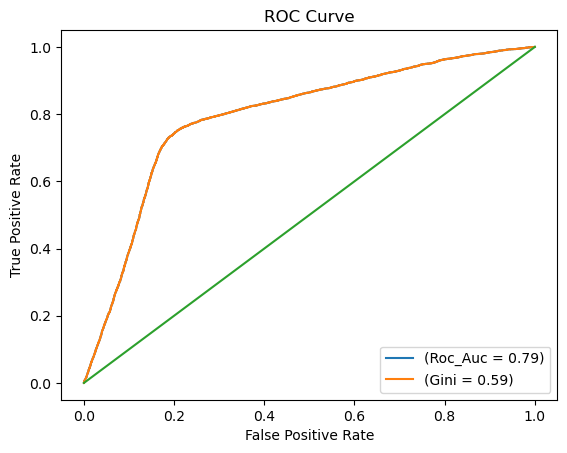

In [21]:
y_prob = clf.predict_proba(X_test)[:,1]

roc_auc = roc_auc_score(y_test, y_prob)
gini = (2*roc_auc_score(y_test, y_prob))-1

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure()

plt.plot(fpr, tpr, label='(Roc_Auc = %0.2f)' % roc_auc)
plt.plot(fpr, tpr, label='(Gini = %0.2f)' % gini)
plt.plot([0, 1], [0, 1])
plt.xlim()
plt.ylim()

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')

plt.legend(loc='lower right')
plt.show()

# 20. Univariate Gini Analysis

In [22]:
variables = []
train_gini_scores = []
test_gini_scores = []

for i in X_train.columns:
    X_train_single_var = X_train[[i]]
    X_test_single_var = X_test[[i]]

    clf.fit(X_train_single_var, y_train)
    y_pred_train_single_var = clf.predict_proba(X_train_single_var)[:, 1]

    train_roc = roc_auc_score(y_train, y_pred_train_single_var)
    train_gini = 2 * train_roc - 1

    y_pred_test_single_var = clf.predict_proba(X_test_single_var)[:, 1]

    test_roc = roc_auc_score(y_test, y_pred_test_single_var)
    test_gini = 2 * test_roc - 1

    variables.append(i)
    train_gini_scores.append(train_gini)
    test_gini_scores.append(test_gini)

results_df = pd.DataFrame({
    'Variable': variables,
    'Train Gini': train_gini_scores,
    'Test Gini': test_gini_scores
})

results_df_sorted = results_df.sort_values(by='Test Gini', ascending=False)

pd.options.display.float_format = '{:.4f}'.format

results_df_sorted

,Variable,Train Gini,Test Gini
10,OutstandingDebt_woe,0.5153,0.5117
5,InterestRate_woe,0.5002,0.5011
9,NumCreditInquiries_woe,0.4459,0.4376
7,Delayfromduedate_woe,0.4229,0.4030
4,NumCreditCard_woe,0.3885,0.3752
6,NumofLoan_woe,0.3542,0.3531
3,NumBankAccounts_woe,0.3173,0.3229
12,PaymentofMinAmount_woe,0.3041,0.2976
8,NumofDelayedPayment_woe,0.2730,0.2740
1,AnnualIncome_woe,0.2478,0.2412


# 21. Final Variable Selection Based on Gini

In [23]:
inputs = data_woe[['OutstandingDebt_woe', 'InterestRate_woe', 'NumCreditInquiries_woe',
       'Delayfromduedate_woe']]
output = data_woe['score']

# 22. Final Model: Train-Test Split

In [24]:
X_train, X_test, y_train, y_test = train_test_split(inputs, output, test_size=0.3, random_state=42)

# 23. Final Model Training

In [25]:
clf = LogisticRegression()
clf.fit(X_train, y_train)

LogisticRegression()

# 24. Final Model Performance

In [26]:
result = evaluate(clf, X_train, y_train, X_test, y_test)

result

(  Dataset    Gini  Precision  Recall
 0   Train 56.6131     0.6300  0.5831
 1    Test 55.9434     0.6268  0.5809,
 array([[15949,  2647],
        [ 3207,  4446]]))

# 25. Deployment: Loading New Customer Data

In [27]:
test_data = pd.read_excel(r'test_data_real_values.xlsx')

test_data

,OutstandingDebt,InterestRate,NumCreditInquiries,Delayfromduedate,CustomerID
0,632.9300,17,0,20,53115
1,3259.1700,24,11,53,35538
2,2313.6000,22,11,55,15150
3,556.8500,16,8,23,65145
4,1115.0600,6,3,16,23224
...,...,...,...,...,...
995,1360.3100,11,8,6,86109
996,1213.2600,11,6,22,62411
997,1509.7200,27,11,18,5554
998,356.6900,18,9,25,70288


# 26. Deployment: WoE Mapping of OutstandingDebt

In [28]:
data.category_OutstandingDebt.value_counts()

category_OutstandingDebt
(1166.23, 1948.98]    21881
(-inf, 566.4]         21880
(566.4, 1166.23]      21873
(1948.98, inf]        21861
Name: count, dtype: int64

In [29]:
ranges = [-np.inf, data['OutstandingDebt'].quantile(0.25), data['OutstandingDebt'].quantile(0.5), data['OutstandingDebt'].quantile(0.75), np.inf]

test_data['category_OutstandingDebt'] = pd.cut(test_data['OutstandingDebt'], bins=ranges)

test_data

,OutstandingDebt,InterestRate,NumCreditInquiries,Delayfromduedate,CustomerID,category_OutstandingDebt
0,632.9300,17,0,20,53115,"(566.4, 1166.23]"
1,3259.1700,24,11,53,35538,"(1948.98, inf]"
2,2313.6000,22,11,55,15150,"(1948.98, inf]"
3,556.8500,16,8,23,65145,"(-inf, 566.4]"
4,1115.0600,6,3,16,23224,"(566.4, 1166.23]"
...,...,...,...,...,...,...
995,1360.3100,11,8,6,86109,"(1166.23, 1948.98]"
996,1213.2600,11,6,22,62411,"(1166.23, 1948.98]"
997,1509.7200,27,11,18,5554,"(1166.23, 1948.98]"
998,356.6900,18,9,25,70288,"(-inf, 566.4]"


In [30]:
test_data = test_data.merge(data[['category_OutstandingDebt','OutstandingDebt_woe']].drop_duplicates(subset='category_OutstandingDebt'), how='left', on='category_OutstandingDebt')

test_data

,OutstandingDebt,InterestRate,NumCreditInquiries,Delayfromduedate,CustomerID,category_OutstandingDebt,OutstandingDebt_woe
0,632.9300,17,0,20,53115,"(566.4, 1166.23]",1.2096
1,3259.1700,24,11,53,35538,"(1948.98, inf]",-1.2232
2,2313.6000,22,11,55,15150,"(1948.98, inf]",-1.2232
3,556.8500,16,8,23,65145,"(-inf, 566.4]",1.2719
4,1115.0600,6,3,16,23224,"(566.4, 1166.23]",1.2096
...,...,...,...,...,...,...,...
995,1360.3100,11,8,6,86109,"(1166.23, 1948.98]",-0.3521
996,1213.2600,11,6,22,62411,"(1166.23, 1948.98]",-0.3521
997,1509.7200,27,11,18,5554,"(1166.23, 1948.98]",-0.3521
998,356.6900,18,9,25,70288,"(-inf, 566.4]",1.2719


# 27. Deployment: WoE Mapping of the Remaining Variables

In [31]:
columns_to_process = ['InterestRate', 'NumCreditInquiries', 'Delayfromduedate']

for i in columns_to_process:
    ranges = [-np.inf, data[i].quantile(0.25), data[i].quantile(0.5), data[i].quantile(0.75), np.inf]
    test_data[f'category_{i}'] = pd.cut(test_data[i], bins=ranges)
    test_data = test_data.merge(data[[f'category_{i}', f'{i}_woe']].drop_duplicates(subset=f'category_{i}'), how='left', on=f'category_{i}')

test_data

,OutstandingDebt,InterestRate,NumCreditInquiries,Delayfromduedate,CustomerID,category_OutstandingDebt,OutstandingDebt_woe,category_InterestRate,InterestRate_woe,category_NumCreditInquiries,NumCreditInquiries_woe,category_Delayfromduedate,Delayfromduedate_woe
0,632.9300,17,0,20,53115,"(566.4, 1166.23]",1.2096,"(13.0, 20.0]",-0.0280,"(-inf, 3.0]",1.1029,"(18.0, 28.0]",-0.1009
1,3259.1700,24,11,53,35538,"(1948.98, inf]",-1.2232,"(20.0, inf]",-1.3762,"(9.0, inf]",-1.0683,"(28.0, inf]",-1.0948
2,2313.6000,22,11,55,15150,"(1948.98, inf]",-1.2232,"(20.0, inf]",-1.3762,"(9.0, inf]",-1.0683,"(28.0, inf]",-1.0948
3,556.8500,16,8,23,65145,"(-inf, 566.4]",1.2719,"(13.0, 20.0]",-0.0280,"(6.0, 9.0]",-0.4761,"(18.0, 28.0]",-0.1009
4,1115.0600,6,3,16,23224,"(566.4, 1166.23]",1.2096,"(-inf, 8.0]",0.9632,"(-inf, 3.0]",1.1029,"(10.0, 18.0]",0.4968
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,1360.3100,11,8,6,86109,"(1166.23, 1948.98]",-0.3521,"(8.0, 13.0]",1.1494,"(6.0, 9.0]",-0.4761,"(-inf, 10.0]",1.0508
996,1213.2600,11,6,22,62411,"(1166.23, 1948.98]",-0.3521,"(8.0, 13.0]",1.1494,"(3.0, 6.0]",0.5585,"(18.0, 28.0]",-0.1009
997,1509.7200,27,11,18,5554,"(1166.23, 1948.98]",-0.3521,"(20.0, inf]",-1.3762,"(9.0, inf]",-1.0683,"(10.0, 18.0]",0.4968
998,356.6900,18,9,25,70288,"(-inf, 566.4]",1.2719,"(13.0, 20.0]",-0.0280,"(6.0, 9.0]",-0.4761,"(18.0, 28.0]",-0.1009


# 28. Deployment: Selection of Model Variables

In [32]:
inputs.columns

Index(['OutstandingDebt_woe', 'InterestRate_woe', 'NumCreditInquiries_woe',
       'Delayfromduedate_woe'],
      dtype='object')

In [33]:
test_data_woe = test_data[['CustomerID','OutstandingDebt_woe', 'InterestRate_woe', 'NumCreditInquiries_woe',
       'Delayfromduedate_woe']]

test_data_woe

,CustomerID,OutstandingDebt_woe,InterestRate_woe,NumCreditInquiries_woe,Delayfromduedate_woe
0,53115,1.2096,-0.0280,1.1029,-0.1009
1,35538,-1.2232,-1.3762,-1.0683,-1.0948
2,15150,-1.2232,-1.3762,-1.0683,-1.0948
3,65145,1.2719,-0.0280,-0.4761,-0.1009
4,23224,1.2096,0.9632,1.1029,0.4968
...,...,...,...,...,...
995,86109,-0.3521,1.1494,-0.4761,1.0508
996,62411,-0.3521,1.1494,0.5585,-0.1009
997,5554,-0.3521,-1.3762,-1.0683,0.4968
998,70288,1.2719,-0.0280,-0.4761,-0.1009


In [34]:
test_data.isnull().sum()

OutstandingDebt                0
InterestRate                   0
NumCreditInquiries             0
Delayfromduedate               0
CustomerID                     0
category_OutstandingDebt       0
OutstandingDebt_woe            0
category_InterestRate          0
InterestRate_woe               0
category_NumCreditInquiries    0
NumCreditInquiries_woe         0
category_Delayfromduedate      0
Delayfromduedate_woe           0
dtype: int64

# 29. Deployment: Probability of Default (PD) Prediction

In [35]:
prob = clf.predict_proba(test_data_woe.iloc[:,1:])[:,1]

In [36]:
test_data_woe['PD'] = prob

test_data_woe

C:\Users\user\AppData\Local\Temp\ipykernel_3796\1660140896.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data_woe['PD'] = prob


,CustomerID,OutstandingDebt_woe,InterestRate_woe,NumCreditInquiries_woe,Delayfromduedate_woe,PD
0,53115,1.2096,-0.0280,1.1029,-0.1009,0.1481
1,35538,-1.2232,-1.3762,-1.0683,-1.0948,0.7135
2,15150,-1.2232,-1.3762,-1.0683,-1.0948,0.7135
3,65145,1.2719,-0.0280,-0.4761,-0.1009,0.2055
4,23224,1.2096,0.9632,1.1029,0.4968,0.0876
...,...,...,...,...,...,...
995,86109,-0.3521,1.1494,-0.4761,1.0508,0.2017
996,62411,-0.3521,1.1494,0.5585,-0.1009,0.2100
997,5554,-0.3521,-1.3762,-1.0683,0.4968,0.5049
998,70288,1.2719,-0.0280,-0.4761,-0.1009,0.2055


# 30. Conclusion

**Objective.** A logistic regression model was built to estimate the probability that a customer has a *Poor* credit score (target = 1; Standard/Good = 0). The dataset contains 87,495 observations, of which 29% are Poor.

**Methodology.**
1. Identifier columns (`ID`, `CustomerID`, `Name`, `SSN`) and `TypeofLoan` (high cardinality) were removed; `CreditScore` was replaced by the binary target.
2. Missing values were imputed with the mode (categoric) and the mean (numeric).
3. All variables were converted using Weight of Evidence (WoE): numeric variables were split into quartile bins, categoric variables kept their own categories.
4. The Kolmogorov-Smirnov test showed that the variables are not normally distributed, so Spearman correlation was used.
5. Variables with |correlation| > 0.1 with the target were kept (14 variables). Only one highly intercorrelated pair was found (`AnnualIncome` and `MonthlyInhandSalary`, > 0.7).
6. A univariate Gini analysis was performed and the four strongest variables (Test Gini > 0.40) were selected.

**Final model.** Variables: `OutstandingDebt`, `InterestRate`, `NumCreditInquiries`, `Delayfromduedate`.

| Dataset | Gini | Precision | Recall |
|---|---|---|---|
| Train | 56.6 | 0.630 | 0.583 |
| Test | 55.9 | 0.627 | 0.581 |

The gap between Train and Test Gini is below 1 point, so the model is stable and does not overfit. The 14-variable model reached a Test Gini of 58.7, so reducing the model to 4 variables costs about 3 Gini points and makes it considerably simpler and easier to explain.

**Deployment.** For 1,000 new customers the raw values were mapped to WoE using the bin boundaries of the training data, and the probability of default (PD) was predicted. Customers with high debt, high interest rate, many credit inquiries and long payment delays receive a PD above 0.70, while customers with low values in all four variables receive a PD below 0.10.